In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sb
from sympy import *

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

import pandas as pd

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42

%run representational_drift.ipynb

In [2]:
def sol_finder2(eta, curr_P, X_ex, x_train, w, z_train):
    found_sol = False
    err_thresh = 0.01
    alpha = 0.00001
    num_attempts = 0
    while found_sol == False or num_attempts == 1000:
        eta[:, curr_P]= np.random.normal(2.5, 0.1, Ny)
        u_train = eta@np.linalg.inv(X_ex)  

        L = (w@np.clip(u_train@x_train, h_min, h_max)-z_train)**2
        epoch= 0
        all_loss = []
        while L > err_thresh:
            eta_train = u_train@x_train
            phi_dir = np.zeros((Ny,1))
            phi_dir[(eta_train>h_min) &(eta_train<h_max)] = 1
            ##grad = 2*(w@np.clip(eta_train, hmin, hmax)-z_train)*w*phi_dir*x_train    ##*u  changing
            grad = (2*(w@np.clip(eta_train, h_min, h_max)-z_train)*w.T*phi_dir)@(x_train.T)
            ##grad = (2*(w@np.clip(eta_train, h_min, h_max)-z_train)*w*phi_dir)[:,None]@(x_train[None,:])
            ##print(grad)
            u_train = u_train- alpha*grad
            L = (w@np.clip(u_train@x_train, h_min, h_max)-z_train)**2
            all_loss.append(L[0][0])
            epoch = epoch + 1
            if epoch >15000:
                if abs(np.array(all_loss)[-10]-np.array(all_loss)[-1])<10**-6:
                    break

        if L<err_thresh:
            found_sol = True
        num_attempts =  num_attempts +1

            
    return(u_train, found_sol)

repetition 0
0  added


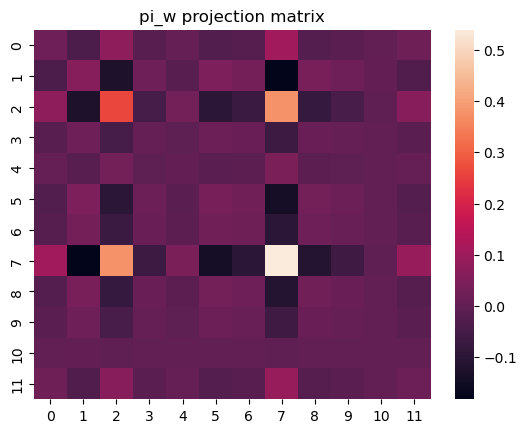

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
1  added


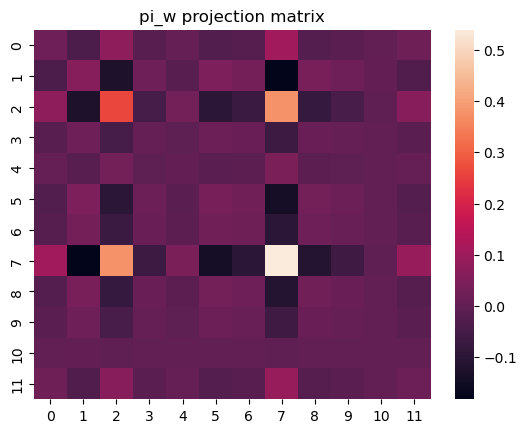

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
2  added


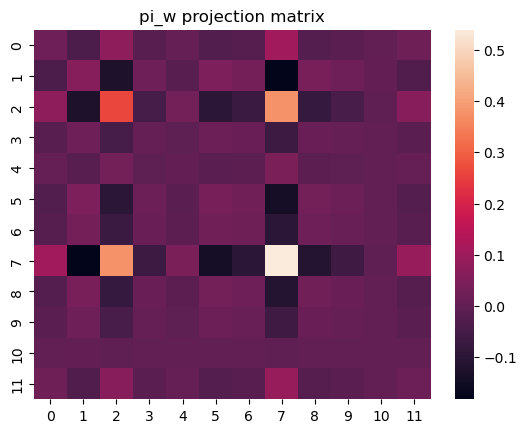

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
3  added


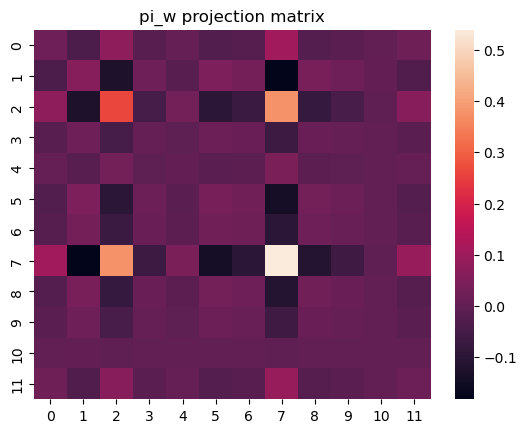

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
4  added


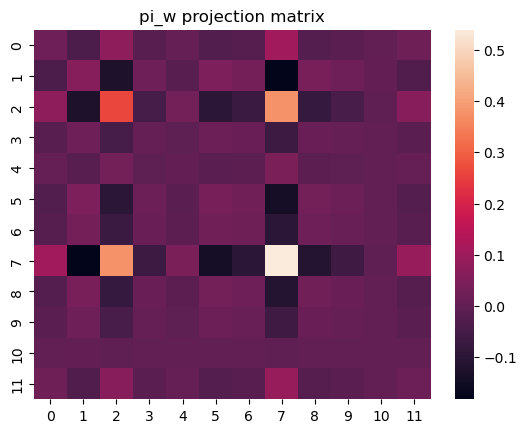

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5  added


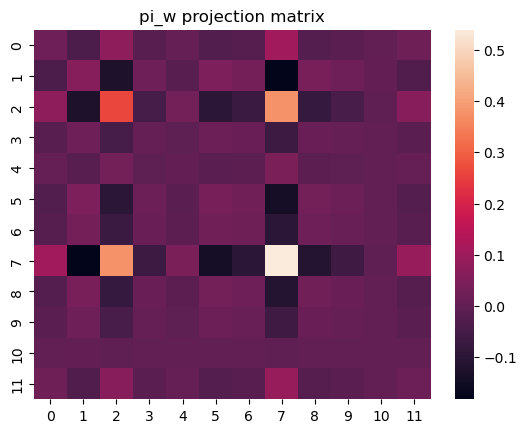

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
6  added


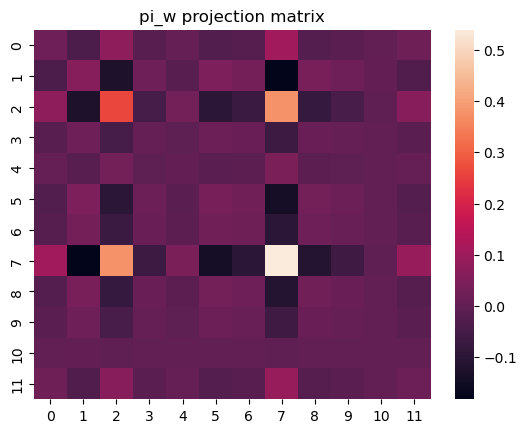

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
7  added


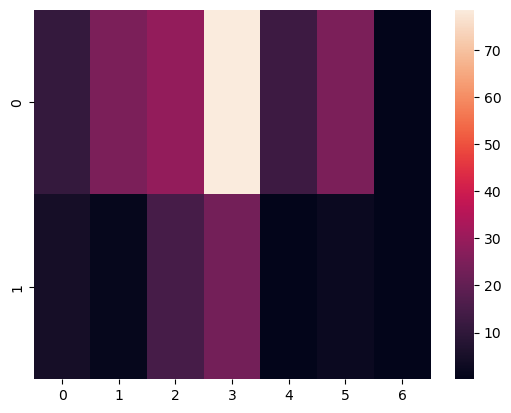

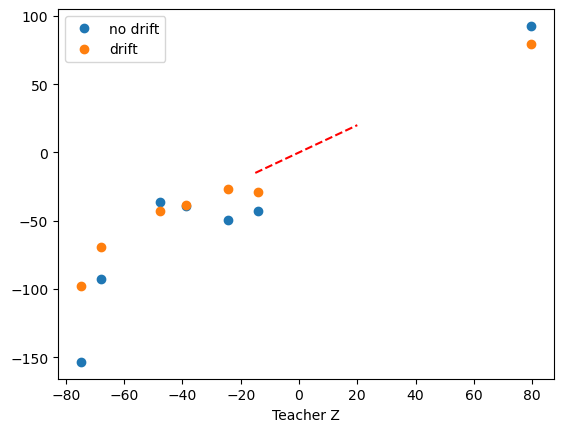

repetition 1
0  added


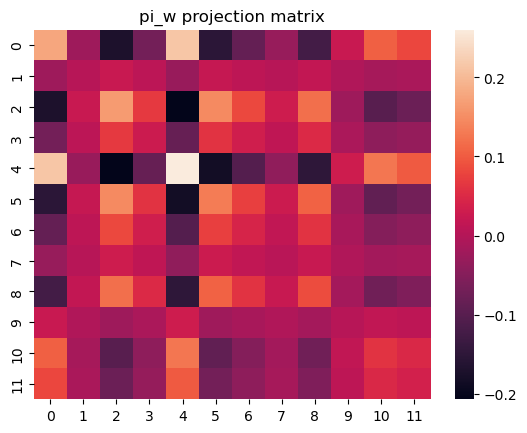

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
1  added


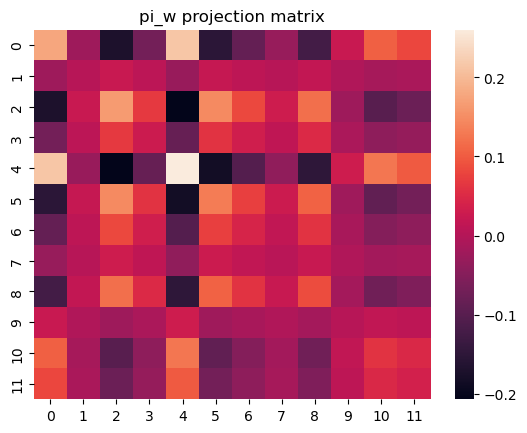

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
2  added


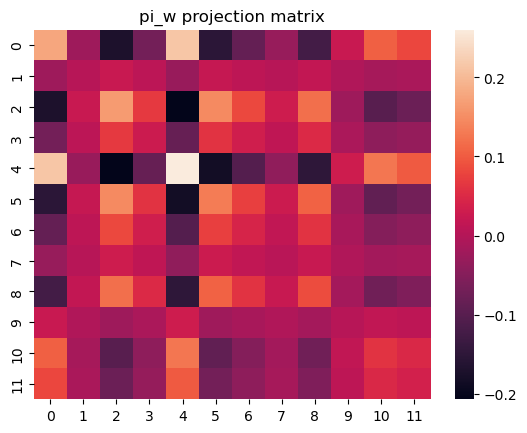

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
3  added


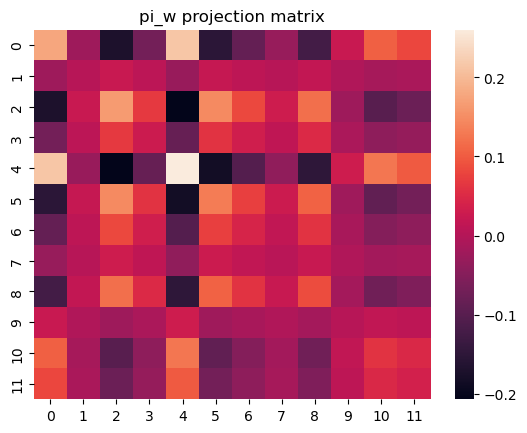

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
4  added


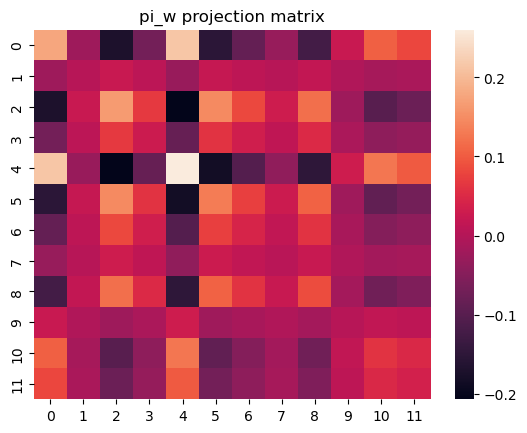

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5  added


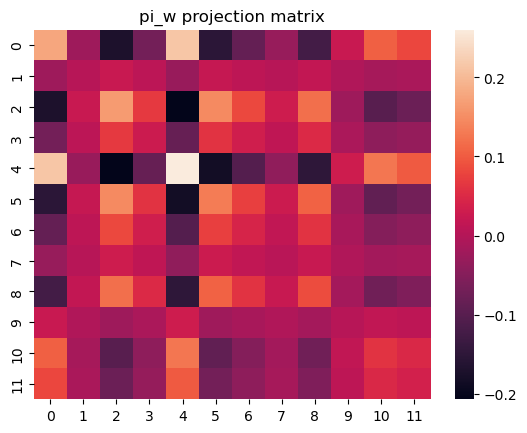

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
6  added


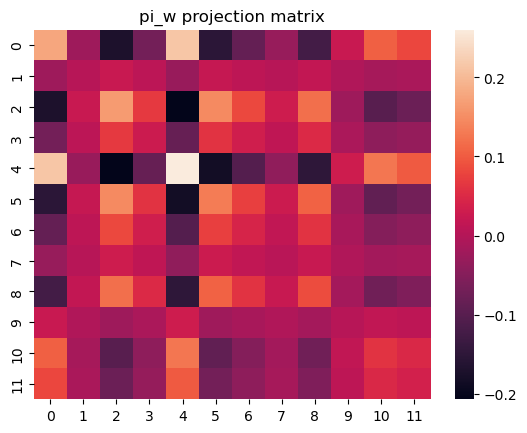

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
7  added


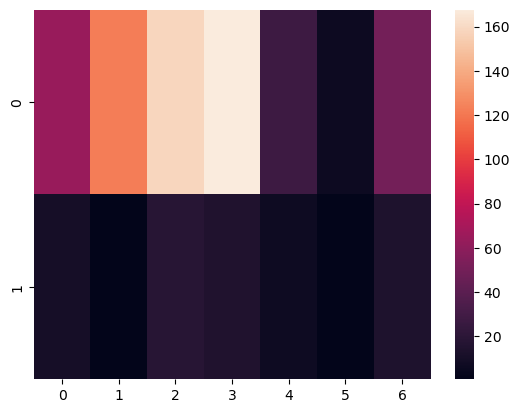

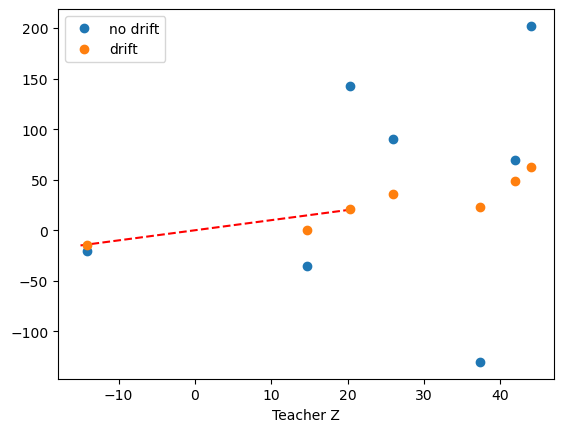

repetition 2
0  added


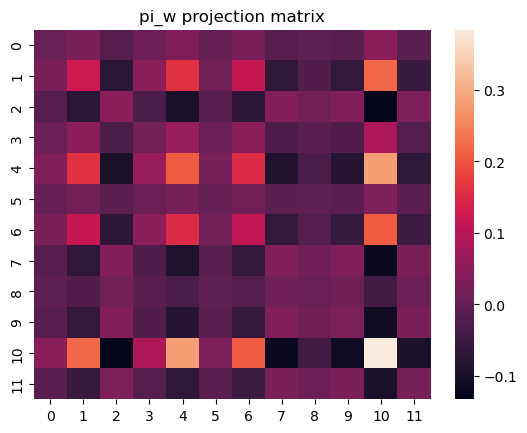

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
1  added


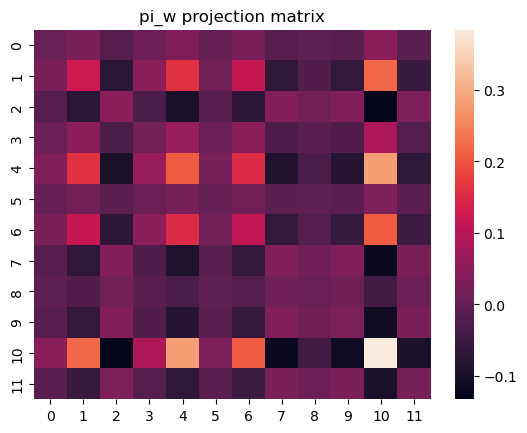

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
2  added


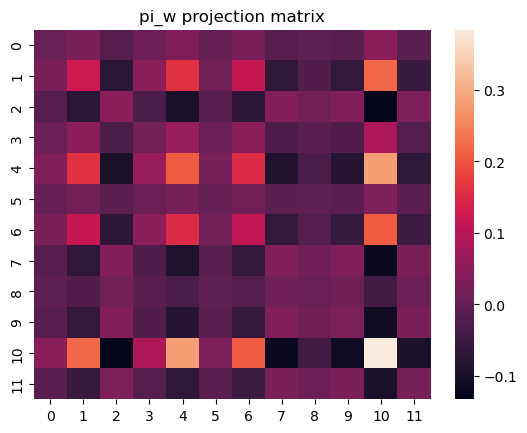

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
3  added


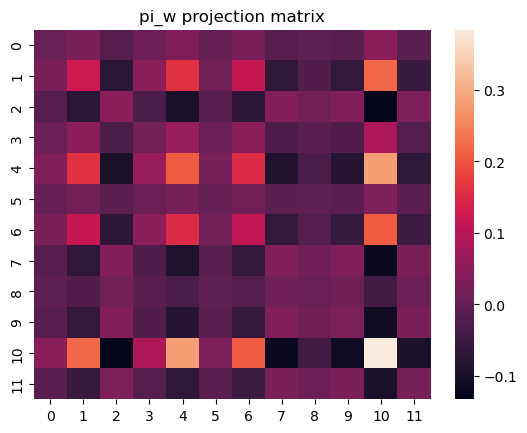

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
4  added


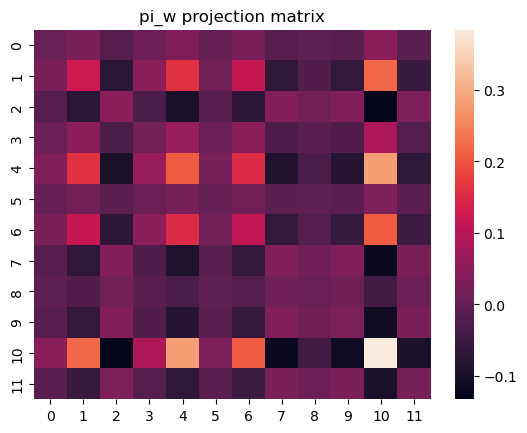

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5  added


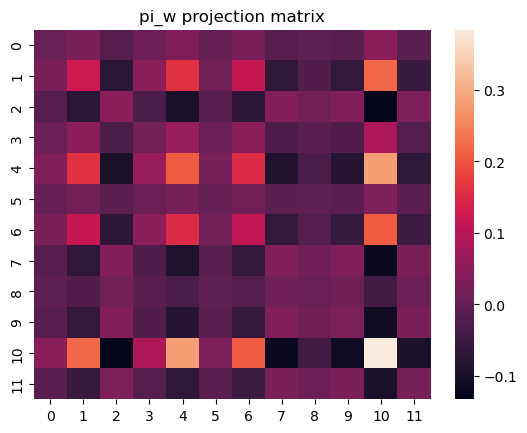

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
6  added


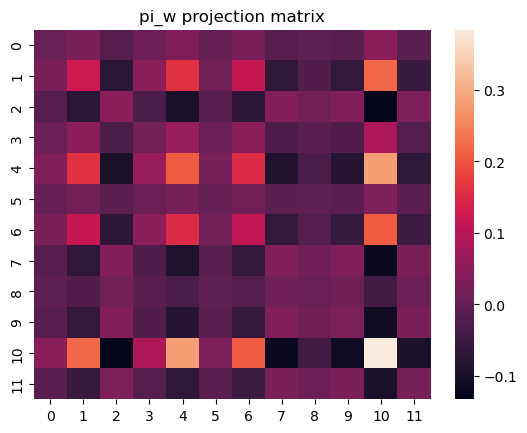

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
7  added


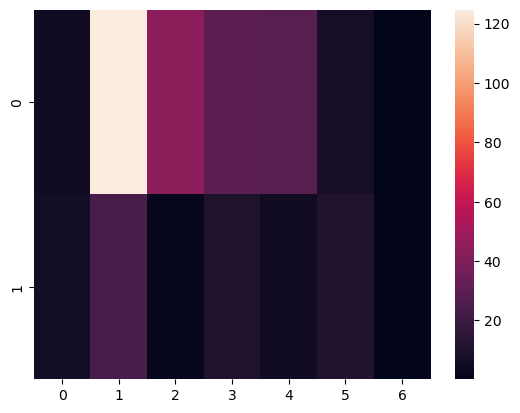

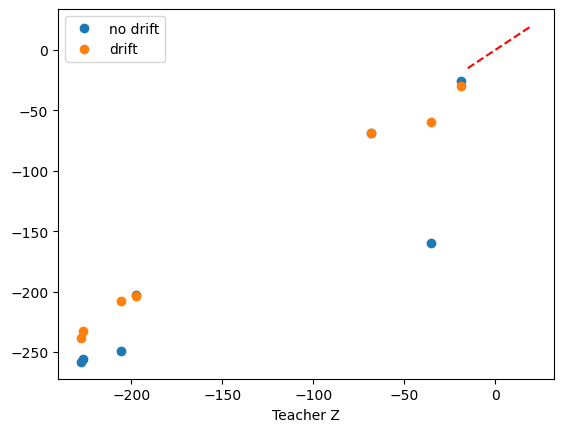

repetition 3
0  added


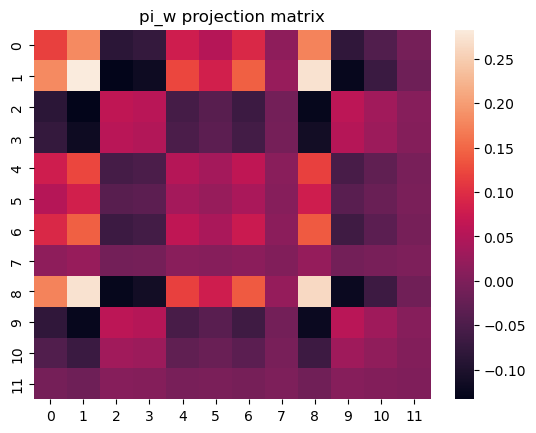

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
1  added


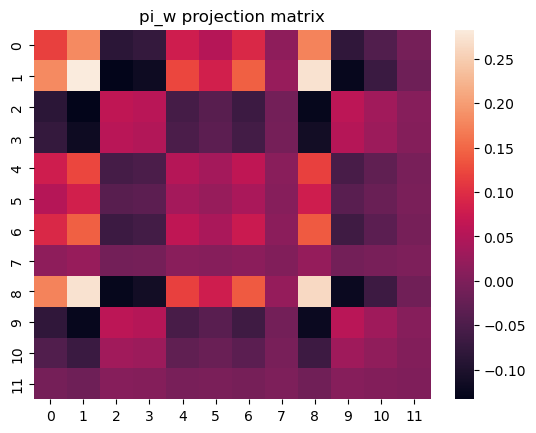

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
2  added


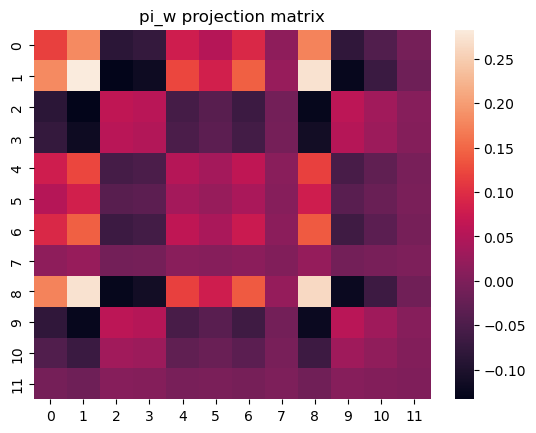

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
3  added


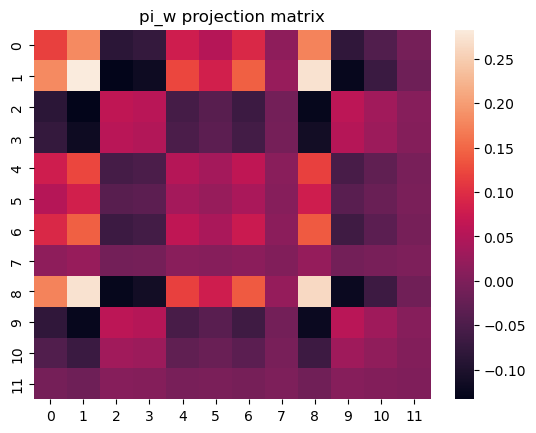

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
4  added


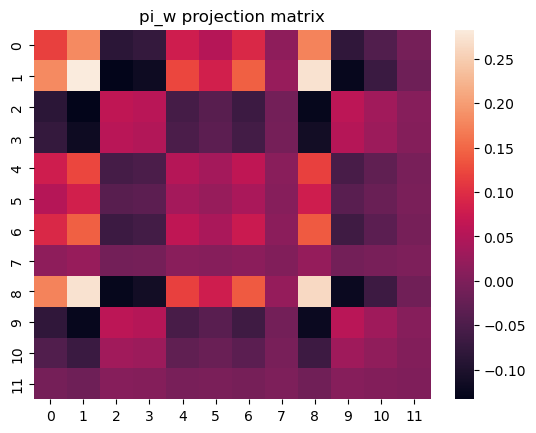

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5  added


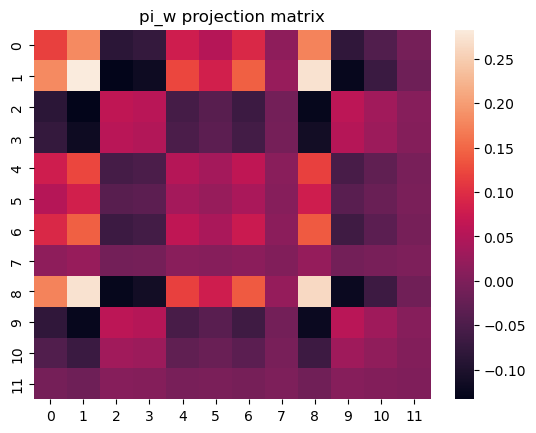

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
6  added


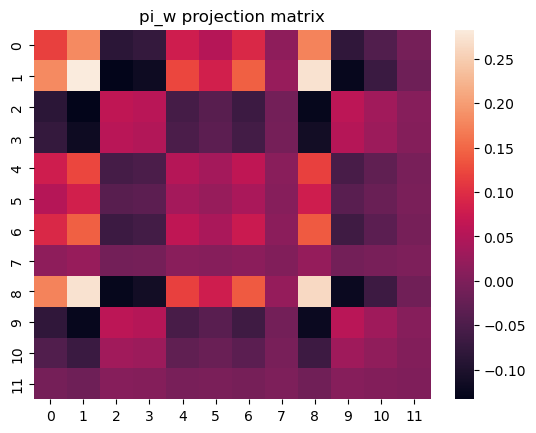

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
7  added


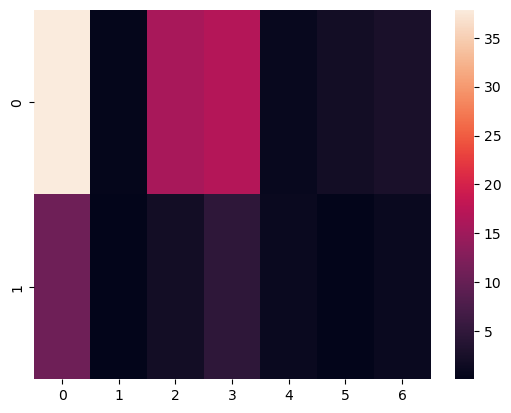

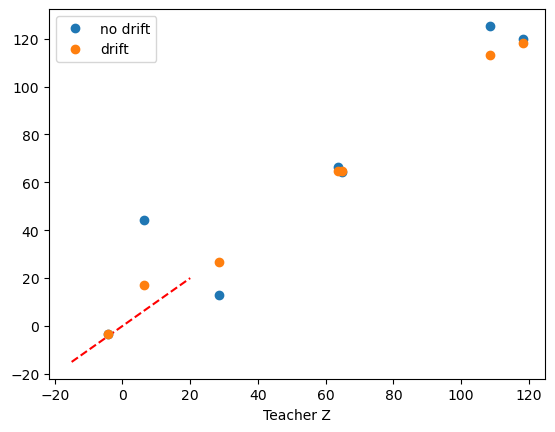

repetition 4
0  added


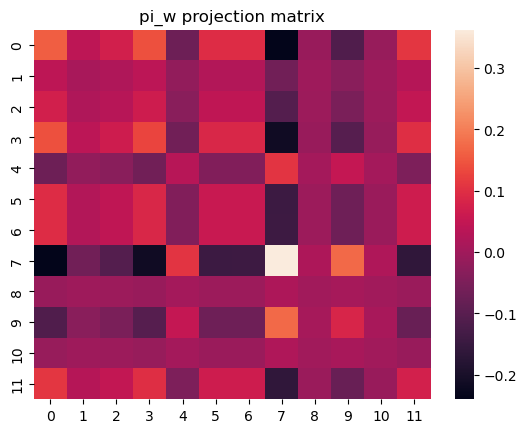

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
1  added


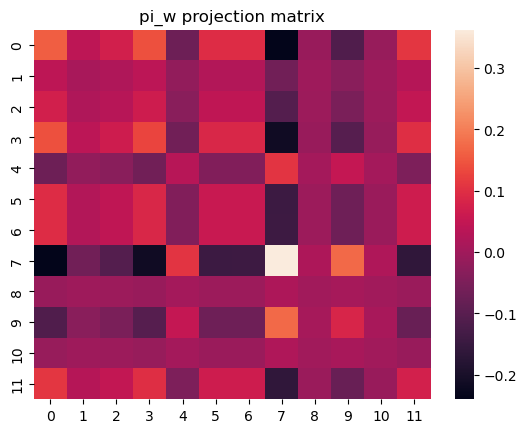

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
2  added


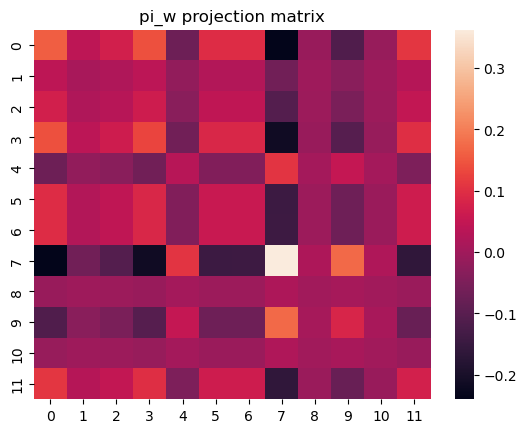

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
3  added


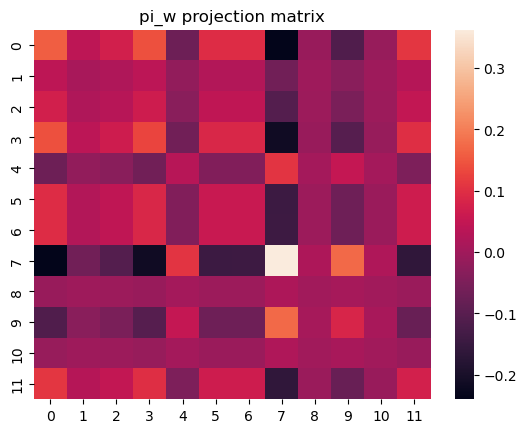

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
4  added


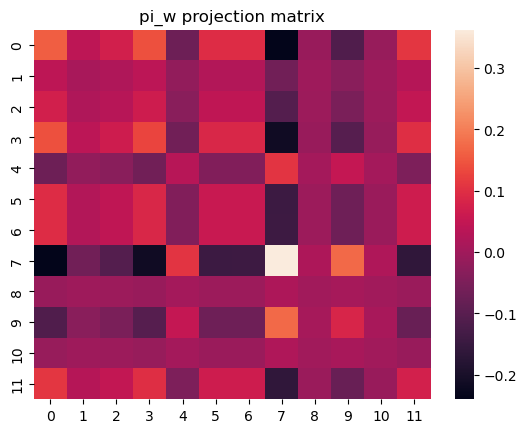

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5  added


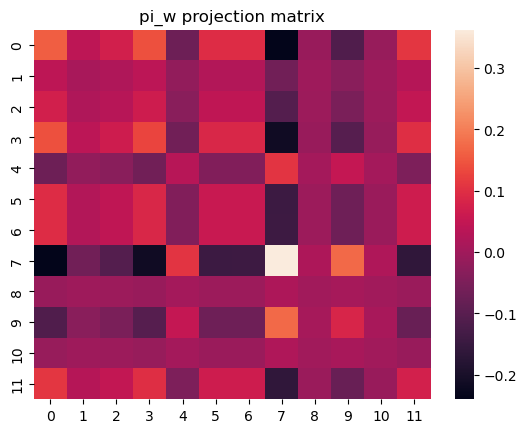

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
6  added


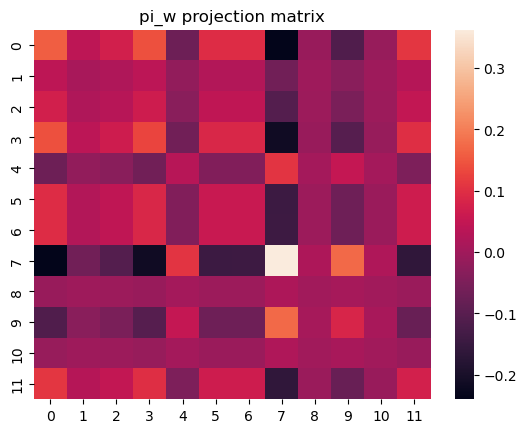

0
100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
7  added


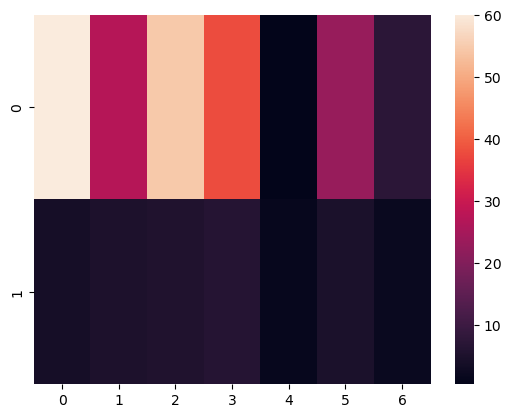

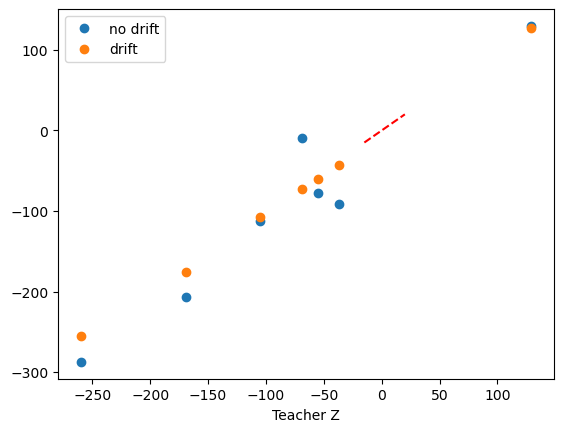

In [5]:
np.random.seed(1)


reps = 5

Nx= 15
Ny = 12
Nz = 1
P = 8
h_min = 0
h_max = 5
U_norm_set = 9000*np.ones(Ny)


eta_clip = False

num_runs = 5000

err_drift= np.array([])
err_no_drift = np.array([])
dist_from_learn= np.array([])

Z_T = np.zeros((reps, P-1))
Z_no_drift = np.zeros_like(Z_T)
Z_drift = np.zeros_like(Z_T)

deta = np.array([])
deta_drift = np.array([])
dY = np.array([])
dY_drift = np.array([])
for rep in range(0, reps):
    print('repetition', rep)

    U = np.random.normal(0, 15, (Ny, Nx))
    U_drift = U.copy()
    U_T = np.random.normal(0, 15, (Ny, Nx))
    W =  np.random.normal(0, 10, (1,Ny))
    W_T = np.copy(W)

    X = np.zeros((0,0))
    ##U_drift, num_saturated, num_inactive, U_sum_all, W_new, W_sum_all, U_all, error_all, U_diff, Y_diff,redos, all_problems = representational_drift_fixed_Unorm(U_drift,X,W, num_runs*6, h_min, h_max, U_norm_set, np.sum(W**2), False, eta_clip)
    
    for curr_P in range(0, P):
        
    
        X_add = np.random.normal(0,1,(Nx, 1))
        if curr_P!=0:
            X = np.column_stack((X, X_add))
        else:
            X = X_add
    
        X_null = scipy.linalg.null_space(X.T)
        X_ex = np.column_stack((X, X_null))   
        eta = U@X_ex
        eta_drift = U_drift@X_ex
        Z = (W@np.clip(U_T@X_add, h_min, h_max))

        
        U, found_sol1 = sol_finder2(eta, curr_P, X_ex, X_add, W, Z)
        deta = np.concatenate((deta, ((U@X)[:,0:curr_P]-eta[:,0:curr_P]).flatten()))
        dY = np.concatenate((dY, (np.clip(U@X, h_min, h_max)[:,0:curr_P] - np.clip(eta, h_min, h_max)[:,0:curr_P]).flatten()))

        U_drift, found_sol2 = sol_finder2(eta_drift, curr_P, X_ex, X_add, W,Z)
        deta_drift = np.concatenate((deta_drift, ((U_drift@X)[:,0:curr_P]-eta_drift[:,0:curr_P]).flatten()))
        dY_drift = np.concatenate((dY_drift, (np.clip(U_drift@X, h_min, h_max)[:,0:curr_P] - np.clip(eta_drift, h_min, h_max)[:,0:curr_P]).flatten()))
          
        if found_sol1== True and found_sol2==True: 
            print(curr_P, ' added')
            
            if curr_P>0:
                
                Z_actual = (W@np.clip(U_T@X, h_min, h_max))[0][0:-1]
                Z_n_d = (W@np.clip(U@X, h_min, h_max))[0][0:-1]
                Z_d = (W@np.clip(U_drift@X, h_min, h_max))[0][0:-1]
                err_drift = np.concatenate((err_drift, abs(Z_d-Z_actual)))
                err_no_drift = np.concatenate((err_no_drift, abs(Z_n_d-Z_actual)))
                dist_from_learn = np.concatenate((dist_from_learn, np.flip(np.arange(1,curr_P+1,1))))
                                       
                                        
            if curr_P != P-1:
                U_norm_set_new = np.maximum(U_norm_set, np.sum(U_drift**2, axis = 1))
                U_drift, num_saturated, num_inactive, U_sum_all, W_new, W_sum_all, U_all, error_all, U_diff, Y_diff,redos, all_problems = representational_drift_fixed_Unorm(U_drift, X,W, num_runs, h_min, h_max, U_norm_set_new, np.sum(W**2), False, eta_clip)
                
        else:
            break
    
    Z_T[rep, 0:curr_P] = (W@np.clip(U_T@X, h_min, h_max))[0][0:-1]
    Z_no_drift[rep,0:curr_P] = (W@np.clip(U@X, h_min, h_max))[0][0:-1]
    Z_drift[rep,0:curr_P] = (W@np.clip(U_drift@X, h_min, h_max))[0][0:-1]
    sb.heatmap(np.array([abs(Z_no_drift[rep]-Z_T[rep]),abs(Z_drift[rep]-Z_T[rep]) ]))
    plt.show()

    plt.plot(np.linspace(-15, 20,1000), np.linspace(-15, 20,1000), linestyle = '--', color = 'red')
    plt.plot(Z_T[rep], Z_no_drift[rep],'o', label = 'no drift')
    plt.plot(Z_T[rep], Z_drift[rep],'o', label = 'drift')
    plt.legend()
    plt.xlabel('Teacher Z')
    plt.show()
    

# Fig 7 F, G, H

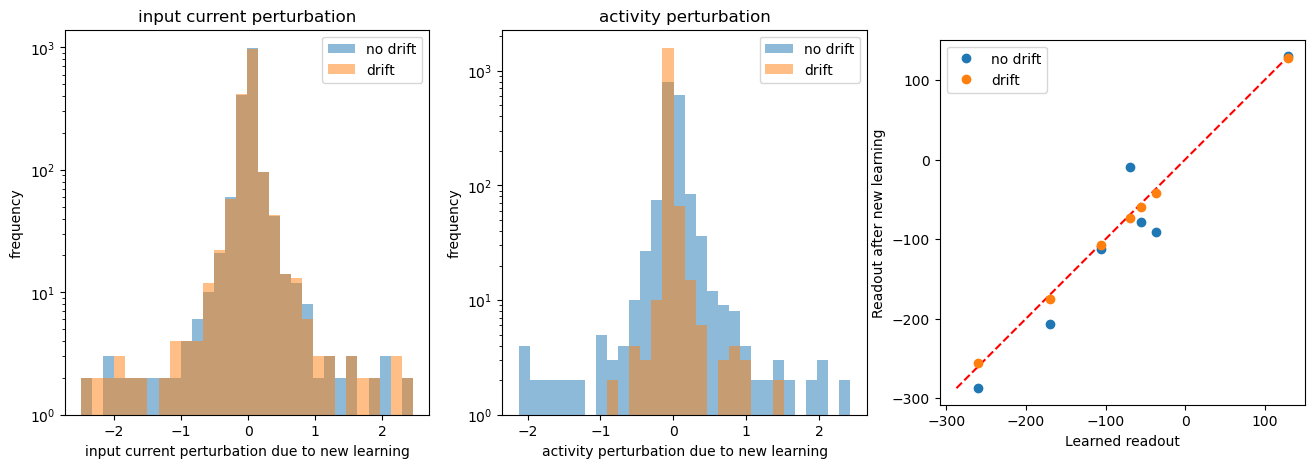

In [6]:
bottom=1
fig, axs = plt.subplots(1,3, figsize = (16,5))
figx = 0
bins=np.histogram(np.hstack((deta,deta_drift)), bins=30)[1]
axs[figx].hist(deta, bins = bins, alpha = 0.5, label = 'no drift',log = True,bottom=bottom)
axs[figx].hist(deta_drift, bins = bins, alpha = 0.5, label = 'drift',log = True,bottom=bottom)
axs[figx].set_title('input current perturbation')
axs[figx].set_xlabel('input current perturbation due to new learning')
axs[figx].set_ylabel('frequency')
axs[figx].legend()


figx = 1
bins=np.histogram(np.hstack((dY,dY_drift)), bins=30)[1]
axs[figx].hist(dY, bins = bins, alpha = 0.5, label = 'no drift', log = True,bottom=bottom)
axs[figx].hist(dY_drift, bins = bins, alpha = 0.5, label = 'drift', log = True,bottom=bottom)
axs[figx].set_title('activity perturbation')
axs[figx].set_xlabel('activity perturbation due to new learning')
axs[figx].set_ylabel('frequency')
axs[figx].legend()

figx = 2
vmin = np.min([np.min(Z_no_drift), np.min(Z_T), np.min(Z_drift)])
vmax = np.min([np.max(Z_no_drift), np.max(Z_T), np.max(Z_drift)])
axs[figx].plot(np.linspace(vmin, vmax,1000), np.linspace(vmin, vmax,1000), linestyle = '--', color = 'red')
axs[figx].plot(Z_T[rep], Z_no_drift[rep],'o', label = 'no drift')
axs[figx].plot(Z_T[rep], Z_drift[rep],'o', label = 'drift')
axs[figx].legend()
axs[figx].set_xlabel('Learned readout')
axs[figx].set_ylabel('Readout after new learning')
axs[figx].set_aspect('equal')

##plt.savefig('../FIGURES/fig_cl2_log.pdf', format='pdf', dpi=500)
plt.show()

# Fig 7 I

In [7]:
cl_robust_all= pd.DataFrame(np.array([dist_from_learn, err_no_drift, err_drift]).T, columns = ['dist from learning', 'err no drift', 'err drift'])

Text(0, 0.5, 'error due to continual learning')

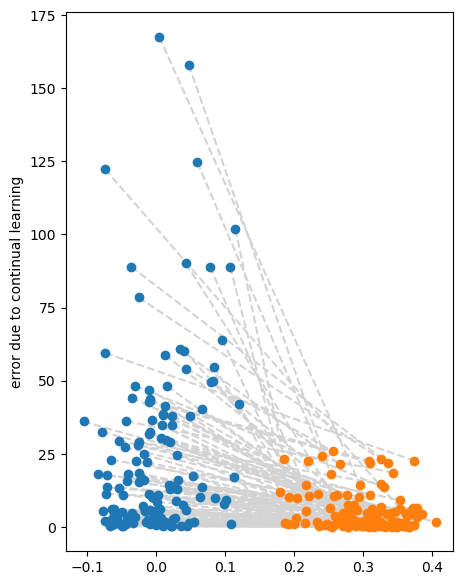

In [8]:
jitter_x1 = np.random.normal(0, 0.05, len(cl_robust_all))
fig,axs = plt.subplots(1, figsize=(5,7))
for i in range(0,len(cl_robust_all)):
    dist_from_learn = cl_robust_all['dist from learning'].iloc[i]
    err_no_drift = cl_robust_all['err no drift'].iloc[i]
    err_drift = cl_robust_all['err drift'].iloc[i]
    axs.plot([-jitter_x1[i],0.3 + jitter_x1[i]], [err_no_drift,err_drift],'--', color = 'lightgray')
axs.plot(np.zeros(len(cl_robust_all))-jitter_x1,cl_robust_all['err no drift'],'o', label = 'no drift')
axs.plot(np.zeros(len(cl_robust_all)) + 0.3+ jitter_x1,cl_robust_all['err drift'],'o', label = 'with drift')
axs.set_ylabel('error due to continual learning')

Text(-3.527777777777777, 0.5, 'difference in error due to continual learning with/without drift')

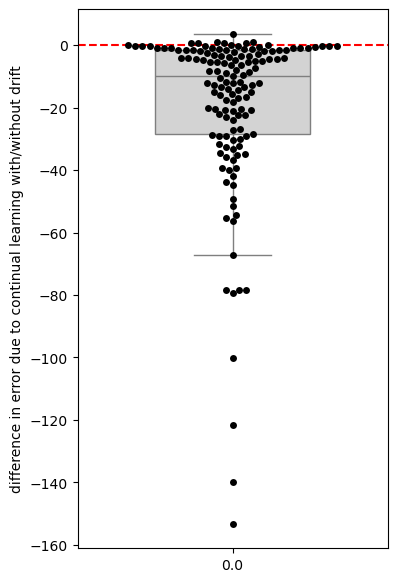

In [15]:
fig,axs = plt.subplots(1, figsize=(4,7))
yvals = np.array(cl_robust_all['err drift']-cl_robust_all['err no drift'])
sb.swarmplot(x= np.zeros(len(cl_robust_all)),y = np.array(cl_robust_all['err drift']-cl_robust_all['err no drift']), ax = axs, color = 'black')

sb.boxplot(x=np.zeros(len(yvals)), y = yvals, showfliers= False, ax = axs, width = 0.5, color = 'lightgray')


axs.axhline(0, linestyle = '--', color = 'red')
axs.set_ylabel('difference in error due to continual learning with/without drift')